# Toy notebook: Autoregressive models for state-to-state collisions in DSMC — with electronic excitation (Keras / TensorFlow)

**Goal:** An autoregressive (AR) network learns from "QCT trajectories" how the internal state $(e, v, J)$ of a molecule changes in a collision, i.e. electronic state, vibration and rotation. It thereby replaces a huge state-to-state table in the DSMC collision step.

**Outline**
1. Model system: diatomic molecule **A₂** with **three electronic states** X, A, B (each an anharmonic oscillator + rigid rotor) colliding with an atom **B**
2. "True" collision physics as a stand-in for QCT, with exactly satisfied detailed balance, including electronic quenching and excitation
3. Synthetic training data
4. AR model $p_\theta(e', v', J' \mid \mathbf c) = p_\theta(e' \mid \mathbf c)\,p_\theta(v' \mid e', \mathbf c)\,p_\theta(J' \mid e', v', \mathbf c)$ with energy masks
5. Training (maximum likelihood)
6. Validation: conditional distributions, detailed balance, **Metropolis-Hastings correction** (exact detailed balance by construction)
7. **0D DSMC heat bath, scenario 1 (heating):** hot translation, molecules in the ground state
8. **0D DSMC heat bath, scenario 2 (quenching):** electronically excited molecules in a cold gas

Units: energies in Kelvin ($k_B = 1$), masses in amu, velocities such that $E = \tfrac12 m v^2$ holds in K. Runs on the CPU in about 20 minutes.

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import time
import numpy as np
import tensorflow as tf
import keras
from keras import layers
import matplotlib.pyplot as plt

SEED = 0
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__,
      "| GPUs:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1794996154.597596  102199 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794996156.612440  102199 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | Keras 3.15.1 | GPUs: []


## 1. Model system: energy levels

$$
\varepsilon(e,v,J) = T_e + \big[G_e(v) - G_e(0)\big] + B\,J(J+1),
\qquad G_e(v) = \omega_e(v+\tfrac12) - \omega_e x_e\,(v+\tfrac12)^2,
\qquad g = g_e\,(2J+1)
$$

| State | $T_e$ [K] | $g_e$ | $\omega_e$ [K] | $\omega_e x_e$ [K] |
|---|---|---|---|---|
| X (ground state) | 0 | 1 | 3000 | 20 |
| A | 9000 | 3 | 2400 | 22 |
| B | 16000 | 2 | 2000 | 25 |

Excited electronic states typically have a lower vibrational frequency because the bond is weaker. With $v = 0\dots9$ and $J = 0\dots49$ the system has 3 × 10 × 50 = 1500 states. For simplicity, the rotational constant is the same for all states.

In [2]:
NE, NV, NJ = 3, 10, 50
EL_NAMES = ["X", "A", "B"]
EL_T = np.array([0.0, 9000.0, 16000.0])      # electronic term energies [K]
EL_G = np.array([1.0, 3.0, 2.0])             # electronic degeneracy
EL_W = np.array([3000.0, 2400.0, 2000.0])    # omega_e [K]
EL_WX = np.array([20.0, 22.0, 25.0])         # omega_e x_e [K]
B_ROT = 8.0

v_idx, J_idx = np.arange(NV), np.arange(NJ)
G_v = lambda w, wx, v: w * (v + 0.5) - wx * (v + 0.5) ** 2
eps_vib = np.array([G_v(w, wx, v_idx) - G_v(w, wx, 0) for w, wx in zip(EL_W, EL_WX)])   # (NE, NV)
eps_rot = B_ROT * J_idx * (J_idx + 1)
g_rot = 2.0 * J_idx + 1

EPS = EL_T[:, None, None] + eps_vib[:, :, None] + eps_rot[None, None, :]   # (NE, NV, NJ)
NS = NE * NV * NJ
eps_flat = EPS.ravel()
g_flat = (EL_G[:, None, None] * np.ones((1, NV, 1)) * g_rot[None, None, :]).ravel()
e_of, v_of, J_of = np.unravel_index(np.arange(NS), (NE, NV, NJ))   # state i -> (e, v, J)
idx = lambda e, v, J: (e * NV + v) * NJ + J

for e in range(NE):
    print(f"{EL_NAMES[e]}: T_e = {EL_T[e]:6.0f} K, eps_vib =", np.round(eps_vib[e]).astype(int))
print("States:", NS, "| max. energy:", eps_flat.max(), "K")

X: T_e =      0 K, eps_vib = [    0  2960  5880  8760 11600 14400 17160 19880 22560 25200]
A: T_e =   9000 K, eps_vib = [    0  2356  4668  6936  9160 11340 13476 15568 17616 19620]
B: T_e =  16000 K, eps_vib = [    0  1950  3850  5700  7500  9250 10950 12600 14200 15750]
States: 1500 | max. energy: 51350.0 K


## 2. "True" collision physics (stand-in for QCT)

Same construction as in the simple notebook, i.e. Metropolis-like. Detailed balance therefore holds **exactly**:

$$
g_i\,E_{\text{tr},i}\;P(f \mid i) \;=\; g_f\,E_{\text{tr},f}\;P(i \mid f),
\qquad E_{\text{tr},f} = E_\text{tot} - \varepsilon_f
$$

with $P(f\mid i) = s(E_\text{tot})\,K_{if}\,\min\!\big(1, \tfrac{g_f E_{\text{tr},f}}{g_i E_{\text{tr},i}}\big)$ for $f \neq i$ and the remainder as an elastic collision. The symmetric coupling now also includes electronic transitions:

$$
K_{if} \propto \exp\!\Big(-\frac{|\Delta e|}{a_e} - \frac{|\Delta J|}{a_J} - \frac{|\Delta v|}{a_v(\Delta e)}\Big),
\qquad a_v(\Delta e) = \begin{cases} a_v & \Delta e = 0 \\ a_v^\text{el} > a_v & \Delta e \neq 0\end{cases}
$$

- **Hierarchy of time scales** as in real molecules: rotation is easy to excite ($a_J$ large, large $\Delta J$ jumps), vibration is stiff ($a_v$ small), electronic transitions are rare ($a_e$ small). Rotation thus relaxes within a few collisions ($\tau_\text{rot} \approx 6$), vibration and electronic excitation within tens to hundreds of collisions. For real N₂, $Z_\text{vib}$ is larger by orders of magnitude. Here it is compressed to keep the runtime short.
- When the electronic state jumps, $v$ may also change strongly. In **quenching**, part of the electronic energy therefore goes directly into ground-state vibration (E-V transfer), not only into translation (E-T). A rough analogue of Franck-Condon effects.

In [3]:
A_V, A_J, A_E, A_V_EL, E0 = 0.3, 10.0, 0.2, 2.0, 3000.0

de = np.abs(e_of[:, None] - e_of[None, :])
dv = np.abs(v_of[:, None] - v_of[None, :])
dJ = np.abs(J_of[:, None] - J_of[None, :])
K = np.exp(-de / A_E - dJ / A_J - dv / np.where(de > 0, A_V_EL, A_V))
np.fill_diagonal(K, 0.0)
K /= K.sum(1).max()                    # row sums <= 1  -> P(i|i) >= 0
del de, dv, dJ

def true_transition_probs(i, Etr):
    # Exact transition probabilities P(f | i, E_tr), shape (N, NS)
    Etot = Etr + eps_flat[i]
    Etr_f = Etot[:, None] - eps_flat[None, :]
    ratio = g_flat[None, :] * np.clip(Etr_f, 0, None) / (g_flat[i] * Etr)[:, None]
    acc = np.where(Etr_f > 0, np.minimum(1.0, ratio), 0.0)
    s = 1.0 - np.exp(-Etot / E0)
    P = s[:, None] * K[i] * acc
    P[np.arange(len(i)), i] = 0.0
    P[np.arange(len(i)), i] = 1.0 - P.sum(1)
    return P

def sample_categorical_np(P, rng):
    c = np.cumsum(P, axis=1)
    u = rng.random(len(P))[:, None] * c[:, -1:]
    return (u > c).sum(1)

def true_sampler(i, Etr, rng=rng):
    return sample_categorical_np(true_transition_probs(i, Etr), rng)

# Test detailed balance of the reference
i_t = rng.integers(0, NS, 2000); f_t = rng.integers(0, NS, 2000)
Etot_t = np.maximum(eps_flat[i_t], eps_flat[f_t]) + rng.uniform(100, 20000, 2000)
Pif = true_transition_probs(i_t, Etot_t - eps_flat[i_t])[np.arange(2000), f_t]
Pfi = true_transition_probs(f_t, Etot_t - eps_flat[f_t])[np.arange(2000), i_t]
lhs = g_flat[i_t] * (Etot_t - eps_flat[i_t]) * Pif
rhs = g_flat[f_t] * (Etot_t - eps_flat[f_t]) * Pfi
m = (lhs > 0) & (i_t != f_t)
print("max. relative deviation from detailed balance:", np.max(np.abs(lhs[m] / rhs[m] - 1)))

# How likely is quenching A(0,0) -> X at E_tr = 2000 K?
P = true_transition_probs(np.array([idx(1, 0, 0)]), np.array([2000.0]))[0].reshape(NE, NV, NJ)
print("P(e' | A(v=0,J=0), E_tr=2000 K):", np.round(P.sum((1, 2)), 4))
print("  of which vibrational distribution in X:", np.round(P[0].sum(1) / P[0].sum(), 3))

max. relative deviation from detailed balance: 2.220446049250313e-16
P(e' | A(v=0,J=0), E_tr=2000 K): [0.0072 0.9928 0.    ]
  of which vibrational distribution in X: [0.474 0.283 0.162 0.081 0.    0.    0.    0.    0.    0.   ]


## 3. Synthetic "QCT" data

Each row is a trajectory $(i, E_\text{tr}) \to f$. Coverage:
- **60 %** of the initial states from a Boltzmann distribution at $T_\text{int} \in [200, 15000]$ K
- **40 %** uniformly distributed over **all** 1500 states, so that strongly non-thermal states such as "electronically excited but rotationally cold" also occur
- $E_\text{tr} \sim$ Gamma(2, $T_\text{tr}$), i.e. collision-weighted, with $T_\text{tr} \in [500, 15000]$ K

The second point matters for the quenching scenario. A network that has only seen Boltzmann initial states would have to extrapolate there.

In [4]:
def boltzmann_states(T, rng):
    w = g_flat[None, :] * np.exp(-eps_flat[None, :] / T[:, None])
    return sample_categorical_np(w, rng)

def make_dataset(n, rng, batch=10000, frac_uniform=0.4):
    I, E, Fs = [], [], []
    for k in range(0, n, batch):
        b = min(batch, n - k)
        i = boltzmann_states(rng.uniform(200, 15000, b), rng)
        uni = rng.random(b) < frac_uniform
        i[uni] = rng.integers(0, NS, uni.sum())
        Etr = rng.gamma(2.0, rng.uniform(500, 15000, b))
        f = true_sampler(i, Etr, rng)
        I.append(i); E.append(Etr); Fs.append(f)
    return np.concatenate(I), np.concatenate(E), np.concatenate(Fs)

t0 = time.time()
N_DATA = 1_000_000
I_all, E_all, F_all = make_dataset(N_DATA, rng)
print(f"{N_DATA} trajectories in {time.time()-t0:.1f}s")
print(f"Fraction elastic: {(I_all == F_all).mean():.3f} | with Δv≠0: {(v_of[I_all] != v_of[F_all]).mean():.3f} "
      f"| with Δe≠0: {(e_of[I_all] != e_of[F_all]).mean():.4f}")

1000000 trajectories in 71.9s
Fraction elastic: 0.349 | with Δv≠0: 0.045 | with Δe≠0: 0.0129


## 4. The autoregressive model

Three heads in **coarse → fine** order:

$$
p_\theta(e', v', J' \mid \mathbf c) =
\text{Softmax}\big(\ell_e(\mathbf c) + M_e\big)_{e'}\cdot
\text{Softmax}\big(\ell_v(\mathbf c, e') + M_v(e')\big)_{v'}\cdot
\text{Softmax}\big(\ell_J(\mathbf c, e', v') + M_J(e', v')\big)_{J'}
$$

- Condition $\mathbf c$: one-hot($e$), one-hot($v$), one-hot($J$), $\log E_\text{tr}$, $E_\text{tot}$
- **Energy masks:** $T_{e'} < E_\text{tot}$, then $T_{e'} + \varepsilon_\text{vib}^{e'}(v') < E_\text{tot}$, then $\varepsilon(e', v', J') < E_\text{tot}$. The ground state $(X, 0, 0)$ is always allowed, so every head has at least one valid choice.
- Because the $v'$ head knows $e'$, it can learn a different vibrational ladder for each electronic state.
- $E_\text{tr}' = E_\text{tot} - \varepsilon(e', v', J')$ is **computed**, not learned. Energy conservation is exact.

The electronic quantum number comes first because it fixes the largest part of the available energy.

In [ ]:
EPS_T = tf.constant(EPS, tf.float32)                                  # (NE, NV, NJ)
EVIB_ABS_T = tf.constant(EL_T[:, None] + eps_vib, tf.float32)         # (NE, NV)
EL_T_T = tf.constant(EL_T, tf.float32)                                # (NE,)
EFLAT_T = tf.constant(eps_flat, tf.float32)                           # (NS,)
NEG = -1e9                                                            # "minus infinity"

def mlp(din, dout, h, depth=3, name=None):
    return keras.Sequential(
        [keras.Input((din,))]
        + [layers.Dense(h, activation="silu") for _ in range(depth)]
        + [layers.Dense(dout)],
        name=name)

class ARCollisionModel(keras.Model):
    # p(e', v', J' | c) = p(e' | c) p(v' | e', c) p(J' | e', v', c)  with energy masks

    def __init__(self, h=256, **kw):
        super().__init__(**kw)
        din = NE + NV + NJ + 2
        self.net_e = mlp(din, NE, h, name="net_e")
        self.net_v = mlp(din + NE, NV, h, name="net_v")
        self.net_J = mlp(din + NE + NV, NJ, h, name="net_J")

    @staticmethod
    def split(i):
        return i // (NV * NJ), (i // NJ) % NV, i % NJ

    def features(self, i, Etr):
        i = tf.cast(i, tf.int32); Etr = tf.cast(Etr, tf.float32)
        e, v, J = self.split(i)
        Etot = Etr + tf.gather(EFLAT_T, i)
        x = tf.concat([tf.one_hot(e, NE), tf.one_hot(v, NV), tf.one_hot(J, NJ),
                       tf.math.log(Etr / 1000.0)[:, None], (Etot / 10000.0)[:, None]], axis=1)
        return x, Etot

    def logits_e(self, x, Etot):
        return tf.where(EL_T_T[None, :] >= Etot[:, None], NEG, self.net_e(x))

    def logits_v(self, x, Etot, e2):
        l = self.net_v(tf.concat([x, tf.one_hot(e2, NE)], axis=1))
        return tf.where(tf.gather(EVIB_ABS_T, e2) >= Etot[:, None], NEG, l)

    def logits_J(self, x, Etot, e2, v2):
        l = self.net_J(tf.concat([x, tf.one_hot(e2, NE), tf.one_hot(v2, NV)], axis=1))
        lev = tf.gather_nd(EPS_T, tf.stack([e2, v2], axis=1))           # (N, NJ)
        return tf.where(lev >= Etot[:, None], NEG, l)

    def log_prob(self, i, Etr, f):
        x, Etot = self.features(i, Etr)
        e2, v2, J2 = self.split(tf.cast(f, tf.int32))
        lp_e = tf.gather(tf.nn.log_softmax(self.logits_e(x, Etot)), e2, batch_dims=1)
        lp_v = tf.gather(tf.nn.log_softmax(self.logits_v(x, Etot, e2)), v2, batch_dims=1)
        lp_J = tf.gather(tf.nn.log_softmax(self.logits_J(x, Etot, e2, v2)), J2, batch_dims=1)
        return lp_e + lp_v + lp_J

    def call(self, inputs):
        # Keras interface: inputs = (i, E_tr, f)  ->  log p(f | i, E_tr)
        i, Etr, f = inputs
        return self.log_prob(i, Etr, f)

    def full_probs(self, i, Etr):
        # Exact model distribution over all NS final states, shape (N, NS), order (e, v, J)
        x, Etot = self.features(i, Etr)
        pe = tf.nn.softmax(self.logits_e(x, Etot))
        out = []
        for e2 in range(NE):
            ee = tf.fill(tf.shape(Etot), e2)
            pv = tf.nn.softmax(self.logits_v(x, Etot, ee))
            for v2 in range(NV):
                vv = tf.fill(tf.shape(Etot), v2)
                pJ = tf.nn.softmax(self.logits_J(x, Etot, ee, vv))
                out.append(pe[:, e2:e2+1] * pv[:, v2:v2+1] * pJ)
        return tf.concat(out, axis=1)

    @tf.function(reduce_retracing=True)
    def sample(self, i, Etr):
        x, Etot = self.features(i, Etr)
        e2 = tf.random.categorical(self.logits_e(x, Etot), 1, dtype=tf.int32)[:, 0]
        v2 = tf.random.categorical(self.logits_v(x, Etot, e2), 1, dtype=tf.int32)[:, 0]
        J2 = tf.random.categorical(self.logits_J(x, Etot, e2, v2), 1, dtype=tf.int32)[:, 0]
        return (e2 * NV + v2) * NJ + J2

model = ARCollisionModel()
_ = model((I_all[:2], E_all[:2], F_all[:2]))     # builds the weights
model.summary()
print("A table would need NS*NS*N_E ≈", f"{NS*NS*100:.1e} entries with 100 energy grid points")

Model: "ar_collision_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ net_e (Sequential)              │ (None, 3)              │       149,251 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ net_v (Sequential)              │ (None, 10)             │       151,818 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ net_J (Sequential)              │ (None, 50)             │       164,658 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 465,727 (1.78 MB)

 Trainable params: 465,727 (1.78 MB)

 Non-trainable params: 0 (0.00 B)

A table would need NS*NS*N_E ≈ 2.2e+08 entries with 100 energy grid points


: 

## 5. Training (maximum likelihood / teacher forcing)

$\mathcal L = -\frac1N \sum \log p_\theta(f \mid i, E_\text{tr})$. All three factors are evaluated in parallel because $e'$ and $v'$ are known from the data.

Keras trick: `call` returns $\log p_\theta$ directly. The loss is `-y_pred`, and `y_true` is a dummy. This way plain `model.fit` works.

In [ ]:
def nll_loss(y_true, y_pred):          # y_pred = log p_theta
    return -y_pred

n_val = 50_000
perm = rng.permutation(N_DATA)
tr, va = perm[n_val:], perm[:n_val]
X_tr = (I_all[tr].astype(np.int32), E_all[tr].astype(np.float32), F_all[tr].astype(np.int32))
X_va = (I_all[va].astype(np.int32), E_all[va].astype(np.float32), F_all[va].astype(np.int32))

EPOCHS, BS = 15, 4096
steps = EPOCHS * int(np.ceil(len(tr) / BS))
lr = keras.optimizers.schedules.CosineDecay(1e-4, decay_steps=steps, warmup_target=3e-3,
                                            warmup_steps=steps // 10)
model.compile(optimizer=keras.optimizers.AdamW(lr, weight_decay=1e-5), loss=nll_loss)

# Lower bound: entropy of the true distribution on the validation data
H_true = 0.0
for k in range(0, n_val, 10000):
    Pv = true_transition_probs(I_all[va[k:k+10000]], E_all[va[k:k+10000]])
    H_true += -(Pv * np.log(np.clip(Pv, 1e-300, None))).sum()
H_true /= n_val
print(f"true conditional entropy (lower bound for the expected val_loss): {H_true:.4f}")

t0 = time.time()
history = model.fit(X_tr, np.zeros(len(tr), np.float32), batch_size=BS, epochs=EPOCHS,
                    validation_data=(X_va, np.zeros(len(va), np.float32)), shuffle=True, verbose=2)
print(f"Training: {time.time()-t0:.0f}s  |  val NLL = {history.history['val_loss'][-1]:.4f}  vs. H_true = {H_true:.4f}")

plt.figure(figsize=(6, 3.5))
plt.plot(history.history["loss"], label="train"); plt.plot(history.history["val_loss"], label="val")
plt.axhline(H_true, color="k", ls=":", label="true entropy")
plt.xlabel("Epoch"); plt.ylabel("NLL [nats]"); plt.legend(); plt.show()

true conditional entropy (lower bound for the expected val_loss): 3.0159
Epoch 1/15
232/232 - 31s - 135ms/step - loss: 3.9275 - val_loss: 3.0868
Epoch 2/15
232/232 - 27s - 116ms/step - loss: 3.0858 - val_loss: 3.0687
Epoch 3/15
232/232 - 28s - 120ms/step - loss: 3.0648 - val_loss: 3.0459
Epoch 4/15
232/232 - 27s - 117ms/step - loss: 3.0494 - val_loss: 3.0395
Epoch 5/15
232/232 - 27s - 117ms/step - loss: 3.0459 - val_loss: 3.0366
Epoch 6/15
232/232 - 27s - 117ms/step - loss: 3.0434 - val_loss: 3.0344
Epoch 7/15


The difference between `val_loss` and the true entropy is the mean KL divergence $\mathbb E\,[\mathrm{KL}(P_\text{true}\,\|\,p_\theta)]$.

## 6a. Validation: conditional distributions

Four cases, including **quenching** $A(0,0) \to ?$ and a collision from the B state. Shown are the marginal distributions of $e'$, $v'$ (summed over $e'$) and $J'$.

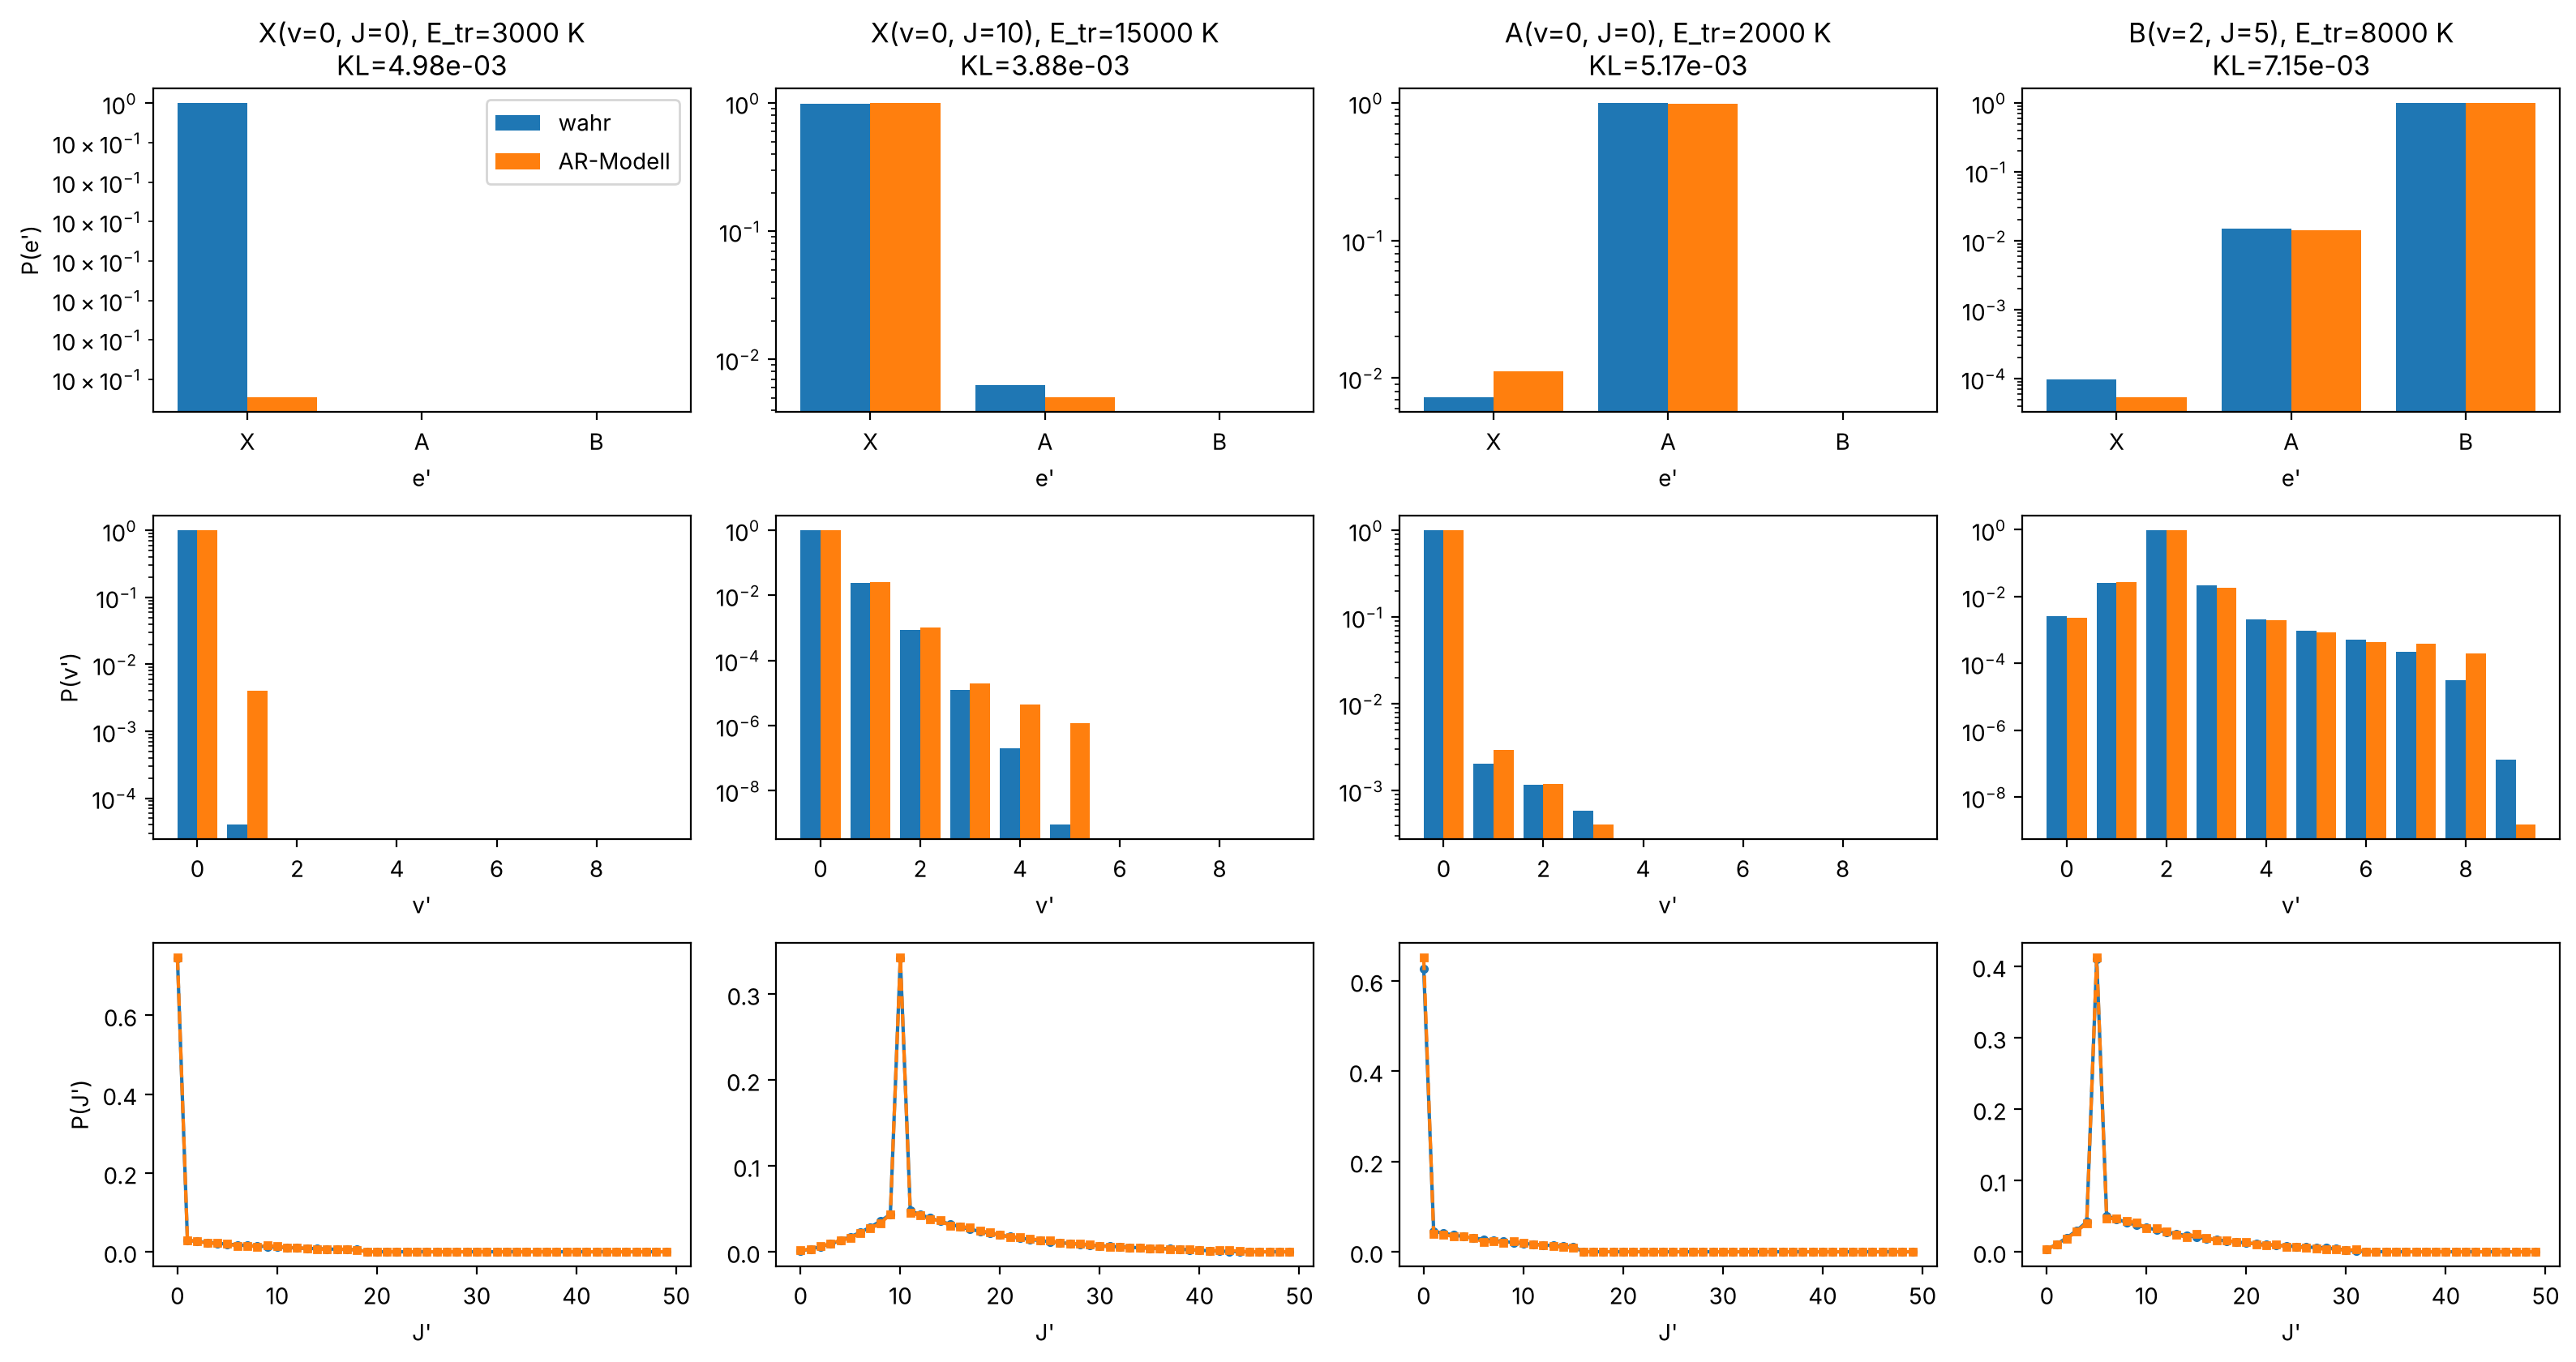

In [ ]:
cases = [(0, 0, 0, 3000.0), (0, 0, 10, 15000.0), (1, 0, 0, 2000.0), (2, 2, 5, 8000.0)]
fig, axes = plt.subplots(3, len(cases), figsize=(16, 8.5))
for c, (e0, v0, J0, Etr0) in enumerate(cases):
    i0 = np.array([idx(e0, v0, J0)]); en0 = np.array([Etr0])
    Pt = true_transition_probs(i0, en0)[0].reshape(NE, NV, NJ)
    Pm = model.full_probs(i0.astype(np.int32), en0.astype(np.float32))[0].numpy().astype(np.float64).reshape(NE, NV, NJ)
    kl = np.sum(Pt * (np.log(np.clip(Pt, 1e-300, None)) - np.log(np.clip(Pm, 1e-300, None))))
    x = np.arange(NE)
    axes[0, c].bar(x - 0.2, Pt.sum((1, 2)), 0.4, label="true")
    axes[0, c].bar(x + 0.2, Pm.sum((1, 2)), 0.4, label="AR-Modell")
    axes[0, c].set_xticks(x, EL_NAMES); axes[0, c].set_yscale("log"); axes[0, c].set_xlabel("e'")
    axes[0, c].set_title(f"{EL_NAMES[e0]}(v={v0}, J={J0}), E_tr={Etr0:.0f} K\nKL={kl:.2e}")
    axes[1, c].bar(v_idx - 0.2, Pt.sum((0, 2)), 0.4); axes[1, c].bar(v_idx + 0.2, Pm.sum((0, 2)), 0.4)
    axes[1, c].set_yscale("log"); axes[1, c].set_xlabel("v'")
    axes[2, c].plot(J_idx, Pt.sum((0, 1)), "o-", ms=3); axes[2, c].plot(J_idx, Pm.sum((0, 1)), "s--", ms=3)
    axes[2, c].set_xlabel("J'")
axes[0, 0].set_ylabel("P(e')"); axes[1, 0].set_ylabel("P(v')"); axes[2, 0].set_ylabel("P(J')")
axes[0, 0].legend(); plt.tight_layout(); plt.show()

In the quenching case (3rd column) the molecule mostly stays in A (elastic or purely rotational). A small fraction goes to X, and then the released energy ends up largely in the **vibration** of X ($v' = 1\dots3$).

**What to watch out for:** The hardest transitions are those **close to the energy threshold**. There the true probability drops steeply because $E_{\text{tr},f} \to 0$, and the network smooths out this drop. Electronic transitions are additionally **rare** (fraction $\sim 10^{-2}$ of collisions). The likelihood therefore "sees" them little, and small relative errors barely show up in the mean NLL. An electronic channel head that is sampled first makes this visible and controllable.

## 6b. Validation: detailed balance

$$
r_{if} = \log\frac{g_i E_{\text{tr},i}\, p_\theta(f\mid i)}{g_f E_{\text{tr},f}\, p_\theta(i\mid f)} \quad (\text{ideally } = 0)
$$

Evaluated separately for transitions with and without a change of electronic state.

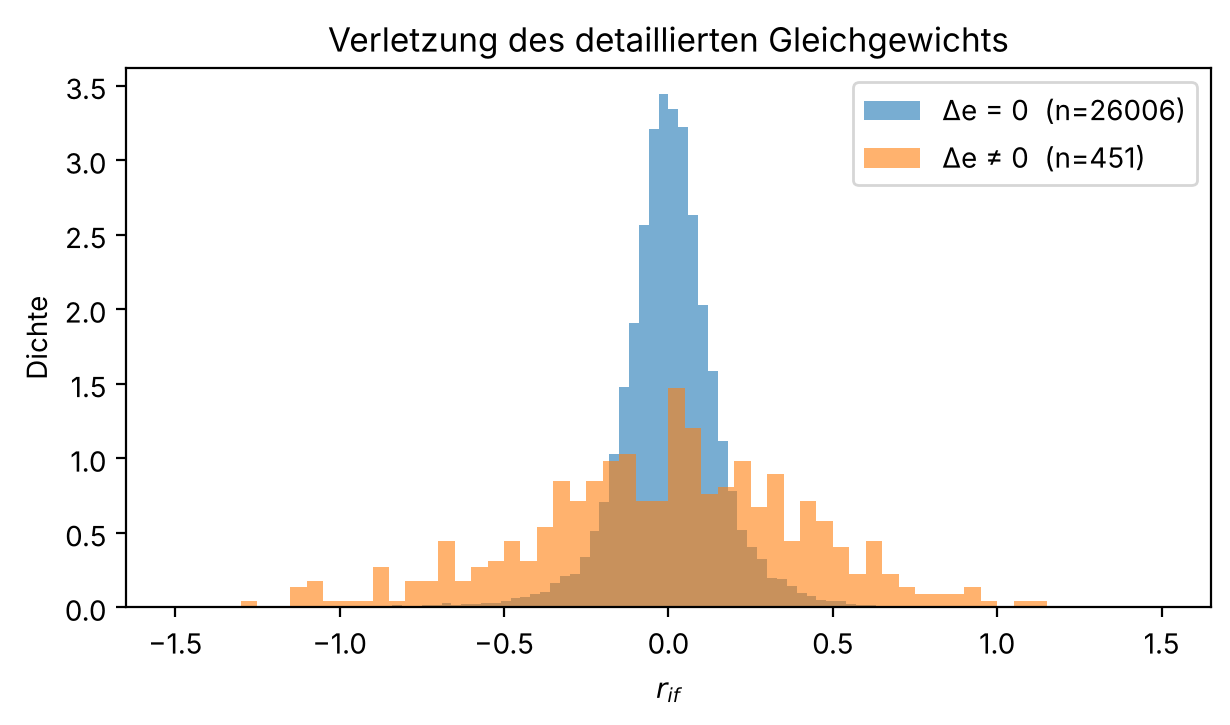

Δe = 0: mean |r| = 0.113, Median r = +0.002
Δe ≠ 0: mean |r| = 0.340, Median r = +0.013


In [ ]:
n = 40000
i_s = boltzmann_states(rng.uniform(500, 15000, n), rng)
Etr_s = rng.gamma(2.0, rng.uniform(1000, 15000, n))
f_s = true_sampler(i_s, Etr_s)
m = f_s != i_s
i_s, f_s, Etr_s = i_s[m], f_s[m], Etr_s[m]
Etot_s = Etr_s + eps_flat[i_s]; Etr_f = Etot_s - eps_flat[f_s]

lp_if = model.log_prob(i_s.astype(np.int32), Etr_s.astype(np.float32), f_s.astype(np.int32)).numpy()
lp_fi = model.log_prob(f_s.astype(np.int32), Etr_f.astype(np.float32), i_s.astype(np.int32)).numpy()
r = np.log(g_flat[i_s] * Etr_s) + lp_if - np.log(g_flat[f_s] * Etr_f) - lp_fi
el = e_of[i_s] != e_of[f_s]

plt.figure(figsize=(7, 3.5))
plt.hist(r[~el], bins=100, range=(-1.5, 1.5), density=True, alpha=0.6, label=f"Δe = 0  (n={np.sum(~el)})")
plt.hist(r[el], bins=60, range=(-1.5, 1.5), density=True, alpha=0.6, label=f"Δe ≠ 0  (n={np.sum(el)})")
plt.xlabel(r"$r_{if}$"); plt.ylabel("Density"); plt.legend(); plt.title("Violation of detailed balance")
plt.show()
print(f"Δe = 0: mean |r| = {np.abs(r[~el]).mean():.3f}, Median r = {np.median(r[~el]):+.3f}")
print(f"Δe ≠ 0: mean |r| = {np.abs(r[el]).mean():.3f}, Median r = {np.median(r[el]):+.3f}")

## 6c. Metropolis-Hastings correction: detailed balance by construction

Instead of taking the final state directly from the network, $q_\theta$ is used only as a **proposal**:

1. $f \sim q_\theta(\cdot \mid i, E_\text{tr})$ (normal AR sampling)
2. Accept with
$$
A_{if} = \min\!\left(1,\; \frac{g_f\,E_{\text{tr},f}\;q_\theta(i \mid f, E_{\text{tr},f})}{g_i\,E_{\text{tr},i}\;q_\theta(f \mid i, E_{\text{tr},i})}\right) = \min\big(1, e^{-r_{if}}\big)
$$
3. On rejection the molecule stays in $i$; the collision was elastic.

For $f \neq i$ we then have $g_i E_{\text{tr},i}\,P(f\mid i) = \min\big(g_i E_{\text{tr},i}\,q_\theta(f\mid i),\; g_f E_{\text{tr},f}\,q_\theta(i\mid f)\big)$, which is symmetric under $i \leftrightarrow f$. **Detailed balance holds exactly**, no matter how good the network is. This is only possible because the AR model provides the exact probability $q_\theta(i\mid f)$ of the reverse process.

**Cost:** two additional `log_prob` evaluations per collision, and slightly altered dynamics. Rejected proposals become elastic collisions, so rates drop wherever the network violates detailed balance. How much is shown by the **acceptance rate**. It can be estimated directly from the $r_{if}$ of 6b:

In [ ]:
A_test = np.minimum(1.0, np.exp(-r))
print(f"expected acceptance rate (inelastic proposals):  Δe = 0: {A_test[~el].mean():.3f}   Δe ≠ 0: {A_test[el].mean():.3f}")

LOGG_T = tf.constant(np.log(g_flat), tf.float32)

@tf.function(reduce_retracing=True)
def mh_step(i, Etr):
    i = tf.cast(i, tf.int32); Etr = tf.cast(Etr, tf.float32)
    f = model.sample(i, Etr)                                              # proposal
    Etr_f = tf.maximum(Etr + tf.gather(EFLAT_T, i) - tf.gather(EFLAT_T, f), 1e-3)
    lq_fwd = model.log_prob(i, Etr, f)                                    # log q(f | i, E_tr)
    lq_bwd = model.log_prob(f, Etr_f, i)                                  # log q(i | f, E_tr')
    log_A = (tf.gather(LOGG_T, f) + tf.math.log(Etr_f) + lq_bwd) \
          - (tf.gather(LOGG_T, i) + tf.math.log(Etr) + lq_fwd)
    accept = tf.math.log(tf.random.uniform(tf.shape(Etr))) < log_A
    return tf.where(accept, f, i), accept, f

class MHSampler:
    # AR proposal + Metropolis-Hastings acceptance, keeps track of acceptance rates
    def __init__(self):
        self.n = {"all": 0, "el": 0}; self.rej = {"all": 0, "el": 0}
    def __call__(self, i, Etr):
        f_new, acc, f_prop = mh_step(tf.constant(i, tf.int32), tf.constant(Etr, tf.float32))
        f_new, acc, f_prop = f_new.numpy().astype(np.int64), acc.numpy(), f_prop.numpy()
        inel = f_prop != i
        el_ = inel & (e_of[f_prop] != e_of[i])
        self.n["all"] += inel.sum(); self.rej["all"] += (inel & ~acc).sum()
        self.n["el"] += el_.sum();   self.rej["el"] += (el_ & ~acc).sum()
        return f_new
    def report(self):
        return (f"Acceptance rate: all inelastic proposals {1 - self.rej['all'] / max(self.n['all'], 1):.3f}, "
                f"electronic (Δe≠0) {1 - self.rej['el'] / max(self.n['el'], 1):.3f}")

expected acceptance rate (inelastic proposals):  Δe = 0: 0.949   Δe ≠ 0: 0.875


## 7. 0D DSMC heat bath

A homogeneous cell with $N_A$ A₂ molecules and $N_B$ B atoms. Only A₂–B collisions occur: NTC with constant $\sigma_\text{ref}$ (hard spheres), final state from the **sampler** (AR model or truth), $E_\text{tr}' = E_\text{tr} + \varepsilon_i - \varepsilon_f$, isotropic scattering in the center-of-mass frame.

Three samplers are compared: the **true** collision physics, the **AR** model directly, and **AR+MH** (AR proposal with Metropolis-Hastings acceptance, section 6c).

Diagnostics:
- $T_\text{tr}$ from the kinetic energy, $T_\text{rot}$ from $\langle \varepsilon_\text{rot}\rangle$ of all molecules
- $T_\text{vib}$ from $\langle \varepsilon_\text{vib}\rangle$ of the molecules **in the ground state X**, because each electronic state has its own vibrational ladder
- **electronic populations** $x_X, x_A, x_B$ directly
- **electronic excitation temperatures**, defined as in spectroscopy via population ratios:
$$
\frac{x_A}{x_X} = \frac{Q_A(T_\text{el}^{A})}{Q_X(T_\text{el}^{A})}, \qquad
\frac{x_B}{x_X} = \frac{Q_B(T_\text{el}^{B})}{Q_X(T_\text{el}^{B})}, \qquad
Q_e(T) = \sum_{v,J} g_e (2J+1)\, e^{-\varepsilon(e,v,J)/T}
$$
  The partition functions $Q_e$ include the vibrational and rotational levels of the respective electronic state. In equilibrium, the definition then yields exactly $T_\text{eq}$. Two properties are important:
  - $T_\text{el}^{A} \neq T_\text{el}^{B}$ means that the electronic states are not in equilibrium **with each other**. There is then no single electronic temperature.
  - If $x_A/x_X$ exceeds the limit for $T \to \infty$ (here $g_A/g_X = 3$), there is a **population inversion**. Formally $T_\text{el} < 0$, and the plot shows a gap. This is exactly what happens at the start of the quenching scenario.

Equilibrium: $\tfrac32 (N_A + N_B)\,T_\text{eq} + N_A\,\langle\varepsilon\rangle(T_\text{eq}) = E_\text{tot}$, where $\langle\varepsilon\rangle$ is averaged over **all** 1500 levels.

In [ ]:
M_A, M_B = 28.0, 14.0
MU = M_A * M_B / (M_A + M_B)

T_grid = np.linspace(20, 40000, 6000)
def mean_energy_curve(levels, g):
    out = np.empty(len(T_grid))
    for k in range(0, len(T_grid), 500):
        w = g[None, :] * np.exp(-(levels[None, :] - levels.min()) / T_grid[k:k+500, None])
        out[k:k+500] = (w * levels).sum(1) / w.sum(1)
    return out
Erot_curve = mean_energy_curve(eps_rot, g_rot)
EvibX_curve = mean_energy_curve(eps_vib[0], np.ones(NV))
Eint_curve = mean_energy_curve(eps_flat, g_flat)
T_from = lambda E, curve: np.interp(E, curve, T_grid)

# log Q_e(T) for each electronic state (log-sum-exp against underflow at small T)
logQ = np.empty((NE, len(T_grid)))
for e in range(NE):
    lev, g = eps_flat[e_of == e], g_flat[e_of == e]
    a = np.log(g)[None, :] - lev[None, :] / T_grid[:, None]
    amax = a.max(1)
    logQ[e] = amax + np.log(np.exp(a - amax[:, None]).sum(1))
logR = logQ - logQ[0]          # log(Q_e / Q_X), monotonically increasing in T

def T_el_from_pops(x, e):
    # Excitation temperature from x_e / x_X. NaN if population is missing or inverted
    if x[e] <= 0 or x[0] <= 0:
        return np.nan
    lr = np.log(x[e] / x[0])
    if lr > logR[e, -1] or lr < logR[e, 0]:
        return np.nan
    return np.interp(lr, logR[e], T_grid)

def boltzmann_pops(T):
    w = g_flat * np.exp(-eps_flat / T); w /= w.sum()
    return (np.bincount(e_of, w, NE), np.bincount(v_of[e_of == 0], w[e_of == 0], NV) / w[e_of == 0].sum(),
            np.bincount(J_of, w, NJ))

def T_equilibrium(E_tot, N_A, N_B):
    return T_grid[np.argmin(np.abs(1.5 * (N_A + N_B) * T_grid + N_A * Eint_curve - E_tot))]

def random_unit(n, rng):
    u = rng.normal(size=(n, 3)); return u / np.linalg.norm(u, axis=1, keepdims=True)

def run_heatbath(sampler, T_tr0, s0, N_A=10000, N_B=10000, n_steps=3000,
                 cand_per_step=3000, seed=1, record_every=20, snap_at=()):
    rng = np.random.default_rng(seed)
    vA = rng.normal(0, np.sqrt(T_tr0 / M_A), (N_A, 3))
    vB = rng.normal(0, np.sqrt(T_tr0 / M_B), (N_B, 3))
    P = M_A * vA.sum(0) + M_B * vB.sum(0)
    vA -= P / (M_A * N_A + M_B * N_B); vB -= P / (M_A * N_A + M_B * N_B)
    state = np.full(N_A, s0, dtype=np.int64)
    g_max, n_coll = 1.0, 0
    rec = {"t": [], "Ttr": [], "Trot": [], "Tvib": [], "TelA": [], "TelB": [], "Etot": [], "xel": [],
           "Erot": [], "Evib": [], "Eel": []}
    snaps = {}
    for step in range(n_steps + 1):
        for s in snap_at:
            if s not in snaps and n_coll / N_A >= s:
                snaps[s] = state.copy()
        if step % record_every == 0:
            Ekin = 0.5 * M_A * (vA**2).sum() + 0.5 * M_B * (vB**2).sum()
            inX = e_of[state] == 0
            rec["t"].append(n_coll / N_A)
            rec["Ttr"].append(Ekin / (1.5 * (N_A + N_B)))
            rec["Trot"].append(T_from(eps_rot[J_of[state]].mean(), Erot_curve))
            rec["Tvib"].append(T_from(eps_vib[0][v_of[state[inX]]].mean(), EvibX_curve) if inX.any() else np.nan)
            rec["Etot"].append(Ekin + eps_flat[state].sum())
            rec["Erot"].append(eps_rot[J_of[state]].mean())
            rec["Evib"].append(eps_vib[e_of[state], v_of[state]].mean())
            rec["Eel"].append(EL_T[e_of[state]].mean())
            x_el = np.bincount(e_of[state], minlength=NE) / N_A
            rec["xel"].append(x_el)
            rec["TelA"].append(T_el_from_pops(x_el, 1))
            rec["TelB"].append(T_el_from_pops(x_el, 2))
        a = rng.permutation(N_A)[:cand_per_step]
        b = rng.permutation(N_B)[:cand_per_step]
        g = np.linalg.norm(vA[a] - vB[b], axis=1)
        g_max = max(g_max, g.max())
        acc = rng.random(len(g)) < g / g_max
        a, b, g = a[acc], b[acc], g[acc]
        Etr = 0.5 * MU * g**2
        i = state[a]
        f = sampler(i, Etr)
        Etr_new = np.maximum(Etr + eps_flat[i] - eps_flat[f], 0.0)   # guard against float32 rounding
        g_new = np.sqrt(2 * Etr_new / MU)[:, None] * random_unit(len(a), rng)
        Vcm = (M_A * vA[a] + M_B * vB[b]) / (M_A + M_B)
        vA[a] = Vcm + M_B / (M_A + M_B) * g_new
        vB[b] = Vcm - M_A / (M_A + M_B) * g_new
        state[a] = f
        n_coll += len(a)
    out = {k: np.array(v) for k, v in rec.items()}
    out["snaps"], out["N"] = snaps, (N_A, N_B)
    return out, state

def model_sampler(i, Etr):
    return model.sample(tf.constant(i, tf.int32), tf.constant(Etr, tf.float32)).numpy().astype(np.int64)

# Plot style per variant: (name, line style)
STYLE = {"true": dict(lw=2.8, alpha=0.4), "AR": dict(ls="--", lw=1.5), "AR+MH": dict(ls=":", lw=2.0)}

def plot_run(runs, title, log_pop=False, T_ylim=None):
    # runs: dict name -> result of run_heatbath, e.g. {"true": ..., "AR": ..., "AR+MH": ...}
    ref = runs["true"]
    T_eq = T_equilibrium(ref["Etot"][0], *ref["N"])
    pe_eq = boltzmann_pops(T_eq)[0]
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
    for key, c in [("Ttr", "C0"), ("Trot", "C1"), ("Tvib", "C2"), ("TelA", "C4"), ("TelB", "C5")]:
        for name, r in runs.items():
            ax[0].plot(r["t"], r[key], color=c, label=f"{key} {name}", **STYLE[name])
    ax[0].axhline(T_eq, color="gray", lw=0.8)
    if T_ylim: ax[0].set_ylim(*T_ylim)
    ax[0].set_xlabel("Collisions per molecule"); ax[0].set_ylabel("Temperature [K]")
    ax[0].set_title(f"{title}: temperatures (T_eq = {T_eq:.0f} K)"); ax[0].legend(ncol=3, fontsize=7)
    for e in range(NE):
        for name, r in runs.items():
            ax[1].plot(r["t"], r["xel"][:, e], color=f"C{e+3}", label=f"{EL_NAMES[e]} {name}", **STYLE[name])
        ax[1].axhline(pe_eq[e], color=f"C{e+3}", lw=0.8, ls="-.")
    if log_pop: ax[1].set_yscale("log"); ax[1].set_ylim(1e-5, 1.5)
    ax[1].set_xlabel("Collisions per molecule"); ax[1].set_ylabel("Population")
    ax[1].set_title(f"{title}: electronic populations (dash-dotted: Boltzmann at T_eq)")
    ax[1].legend(ncol=3, fontsize=7)
    plt.tight_layout(); plt.show()

    late = slice(len(ref["t"]) * 3 // 4, None)          # time average over the last quarter
    print(f"T_eq = {T_eq:.0f} K,  Boltzmann x_el = {np.round(pe_eq, 4)}")
    for name, r in runs.items():
        print(f"  {name:6s}: T_tr={r['Ttr'][late].mean():.0f}  T_rot={r['Trot'][late].mean():.0f}  "
              f"T_vib(X)={np.nanmean(r['Tvib'][late]):.0f}  T_el(A)={np.nanmean(r['TelA'][late]):.0f}  "
              f"T_el(B)={np.nanmean(r['TelB'][late]):.0f}  x_el={np.round(r['xel'][late].mean(0), 4)}")
    for name, r in runs.items():
        if name != "true":
            print(f"  Energy conservation (rel. drift) {name}: {abs(r['Etot'][-1] / r['Etot'][0] - 1):.1e}")
    return T_eq

def plot_energy_relaxation(runs, title):
    # Normalized energy content per mode: 0 = start, 1 = final value (average over the last quarter)
    fig, ax = plt.subplots(figsize=(9, 4.2))
    print(f"1/e relaxation times (energy) in collisions per molecule, {title}:")
    for key, c, lab in [("Erot", "C1", "Rotation"), ("Evib", "C2", "Vibration"), ("Eel", "C4", "electronic")]:
        taus = {}
        for name, r in runs.items():
            E = r[key]; E_end = E[-len(E) // 4:].mean()
            y = (E - E[0]) / (E_end - E[0])
            ax.plot(r["t"][1:], y[1:], color=c, label=f"{lab} {name}", **STYLE[name])   # t=0 does not fit on the log axis
            k = np.argmax(y > 1 - np.exp(-1))
            taus[name] = np.interp(1 - np.exp(-1), [y[k-1], y[k]], [r["t"][k-1], r["t"][k]])
        print(f"  {lab:13s} " + "   ".join(f"{n} = {t:6.1f}" for n, t in taus.items()))
    ax.axhline(1 - np.exp(-1), color="gray", lw=0.8, ls=":")
    ax.set_xscale("log"); ax.set_xlim(runs["true"]["t"][1], None)
    ax.set_xlabel("Collisions per molecule (log)"); ax.set_ylabel("normalized energy content")
    ax.set_title(f"{title}: relaxation of energy contents"); ax.legend(ncol=3, fontsize=7)
    plt.show()

### Scenario 1: Heating

Start: $T_\text{tr} = 10000$ K, all molecules in $X(v{=}0, J{=}0)$. Expected order: **rotation first** (a few collisions), then vibration and electronic excitation.

**Caution when reading the temperature curves:** $T_\text{vib}$ and $T_\text{el}$ quickly jump to several thousand Kelvin at the start, even though hardly any energy is in these modes. This is due to the nonlinear definition. For large quantum spacings ($\hbar\omega \approx 3000$ K), roughly $\langle\varepsilon_\text{vib}\rangle \approx \hbar\omega\,e^{-\hbar\omega/T}$. Just a few percent of molecules in $v=1$ therefore mean $T_\text{vib} \approx 1000$ K. To answer "which mode relaxes first", the **normalized energy content** is the right measure (second plot, log time axis).

true: 111s


AR: 81s


AR+MH: 166s
Acceptance rate: all inelastic proposals 0.944, electronic (Δe≠0) 0.809


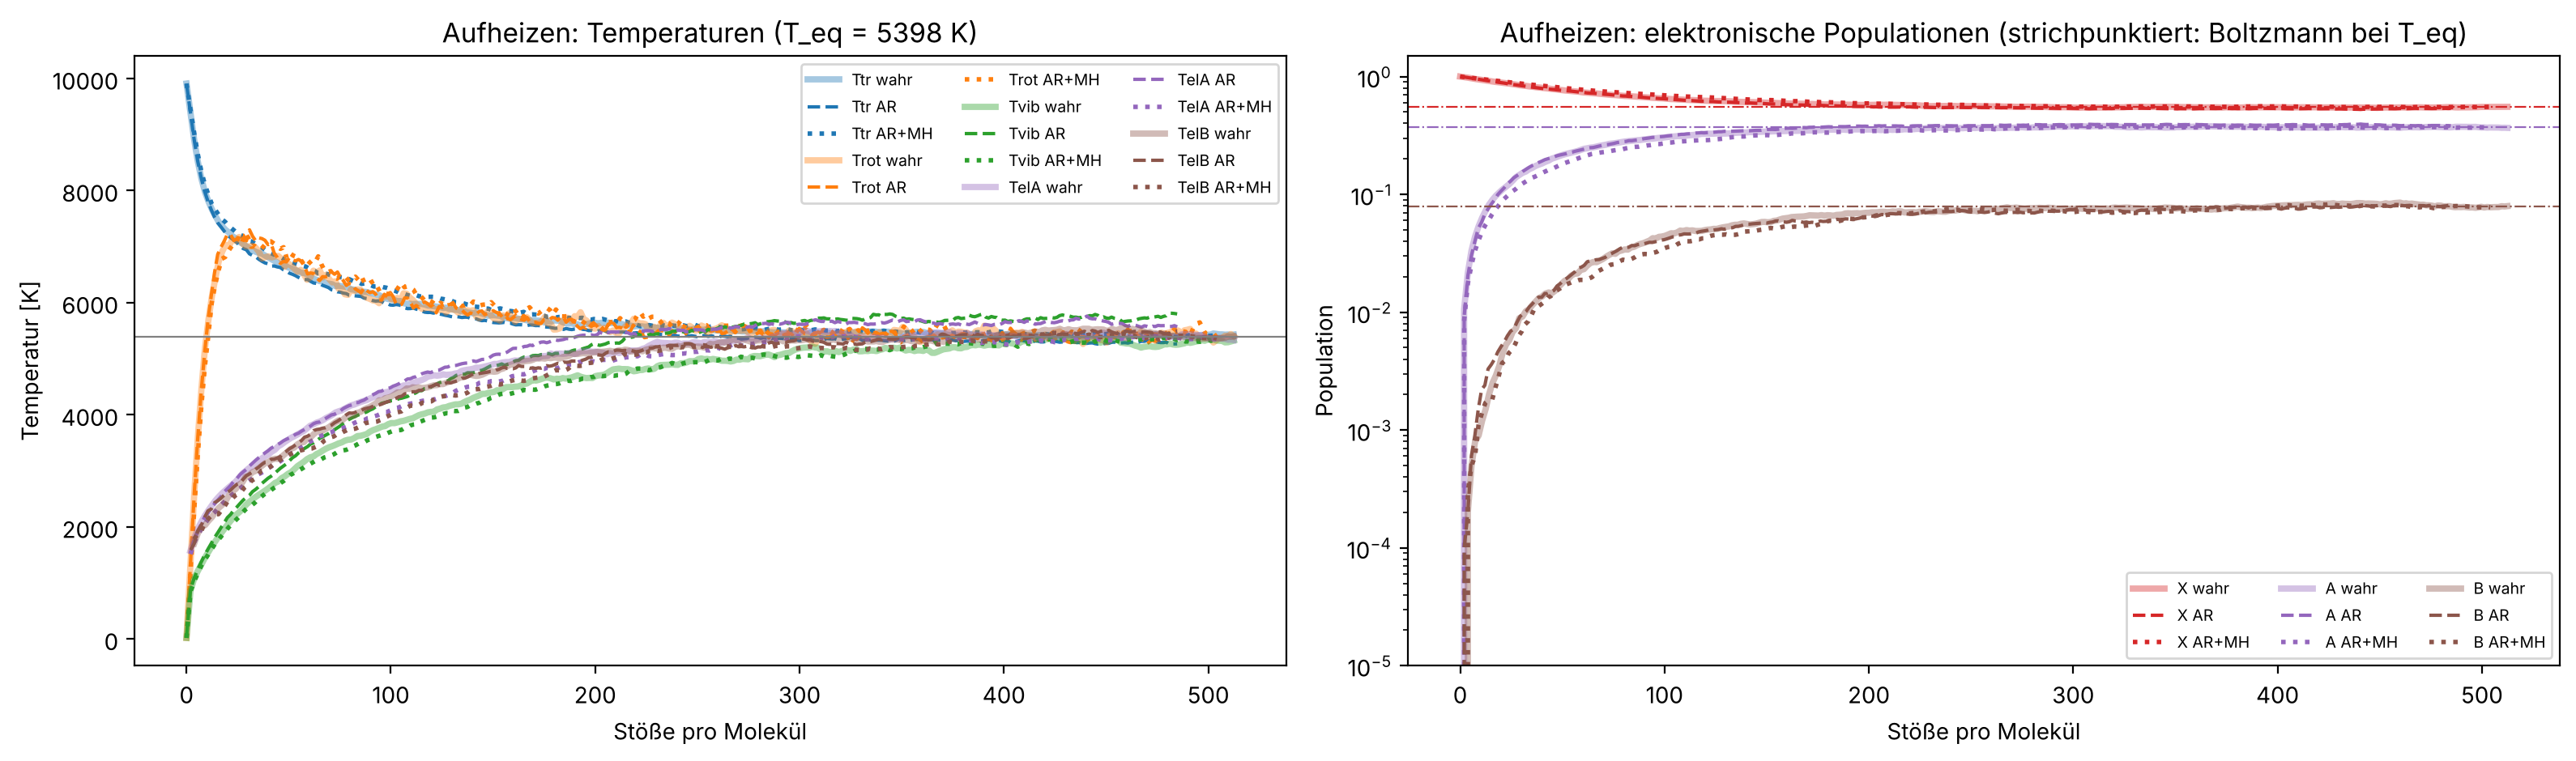

T_eq = 5398 K,  Boltzmann x_el = [0.5496 0.3716 0.0788]
  true  : T_tr=5415  T_rot=5414  T_vib(X)=5298  T_el(A)=5406  T_el(B)=5457  x_el=[0.5477 0.3712 0.0811]
  AR    : T_tr=5304  T_rot=5395  T_vib(X)=5729  T_el(A)=5635  T_el(B)=5440  x_el=[0.5341 0.3876 0.0783]
  AR+MH : T_tr=5428  T_rot=5433  T_vib(X)=5309  T_el(A)=5340  T_el(B)=5397  x_el=[0.5533 0.3674 0.0793]
  Energy conservation (rel. drift) AR: 2.0e-14
  Energy conservation (rel. drift) AR+MH: 2.1e-14
1/e relaxation times (energy) in collisions per molecule, Heating:
  Rotation      true =    4.8   AR =    4.7   AR+MH =    5.3
  Vibration     true =   75.8   AR =   71.7   AR+MH =   89.3
  electronic    true =   74.1   AR =   76.4   AR+MH =   94.6


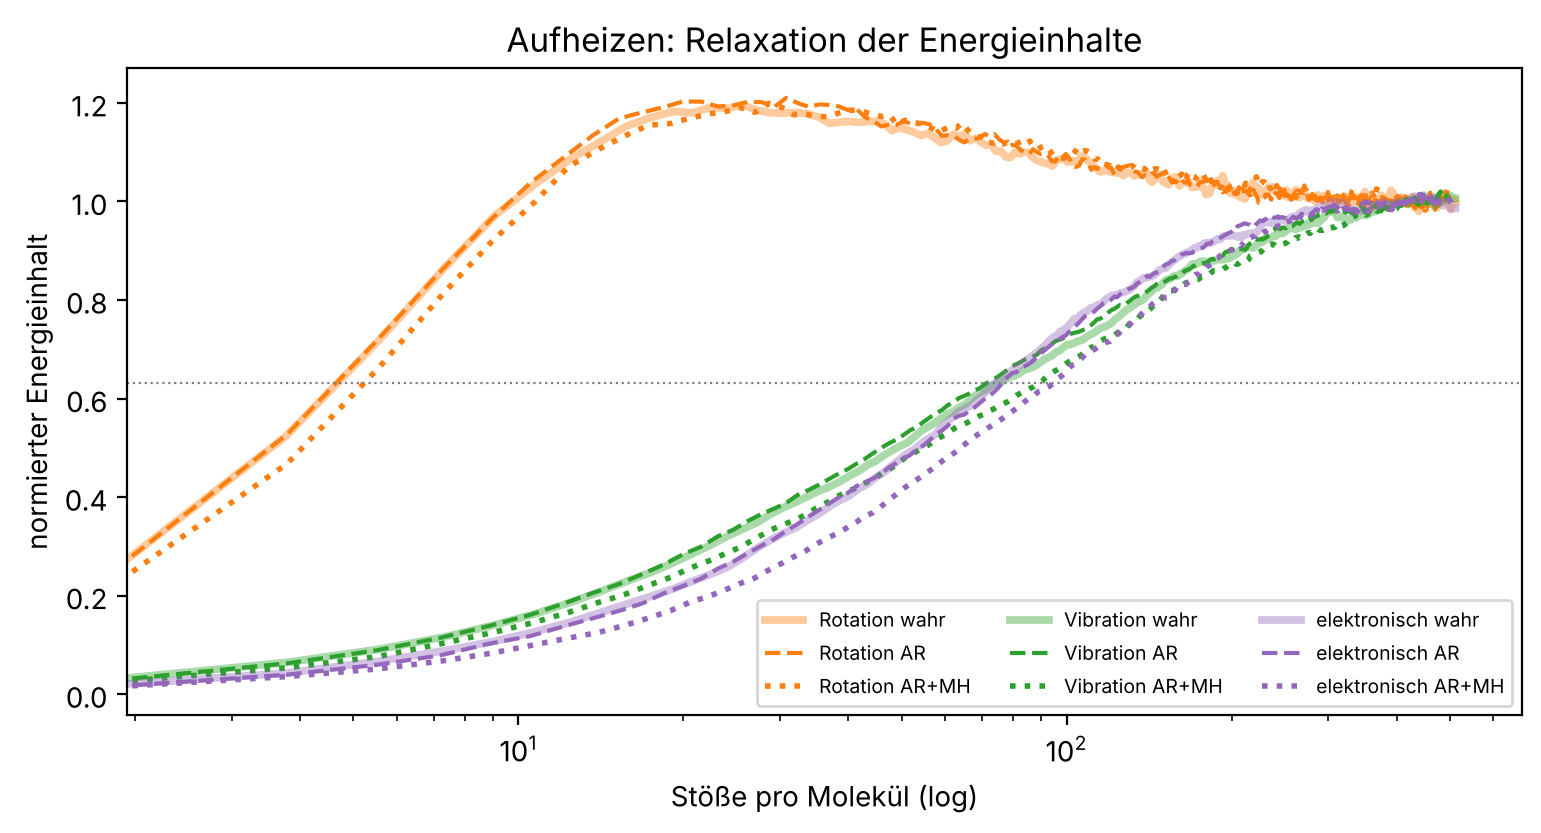

In [ ]:
rng_true = np.random.default_rng(7)
runs1, final1 = {}, {}
for name, sampler in [("true", lambda i, e: true_sampler(i, e, rng_true)),
                      ("AR", model_sampler),
                      ("AR+MH", (mh1 := MHSampler()))]:
    t0 = time.time()
    runs1[name], final1[name] = run_heatbath(sampler, 10000.0, idx(0, 0, 0), n_steps=7000)
    print(f"{name}: {time.time()-t0:.0f}s")
print(mh1.report())
T_eq1 = plot_run(runs1, "Heating", log_pop=True)
plot_energy_relaxation(runs1, "Heating")

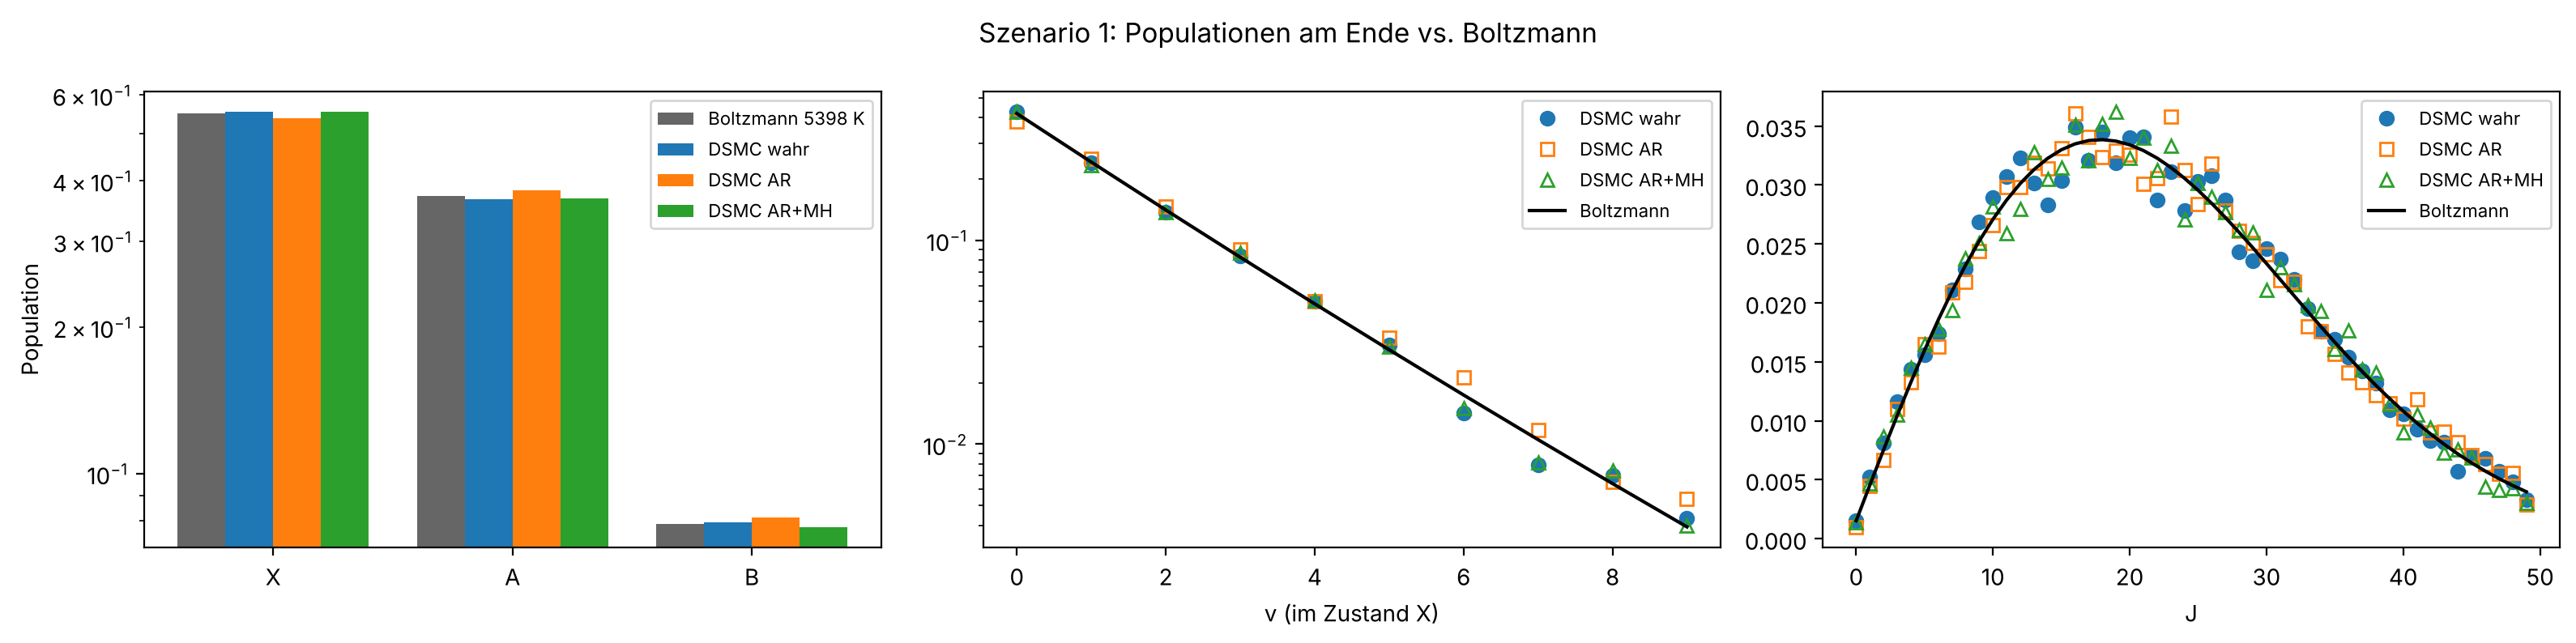

In [ ]:
pe_eq, pvX_eq, pJ_eq = boltzmann_pops(T_eq1)
N1 = runs1["true"]["N"][0]
MARK = {"true": dict(marker="o", ls=""), "AR": dict(marker="s", mfc="none", ls=""), "AR+MH": dict(marker="^", mfc="none", ls="")}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
x = np.arange(NE); w = 0.2
ax[0].bar(x - 1.5 * w, pe_eq, w, color="k", alpha=0.6, label=f"Boltzmann {T_eq1:.0f} K")
for k, (name, st) in enumerate(final1.items()):
    ax[0].bar(x + (k - 0.5) * w, np.bincount(e_of[st], minlength=NE) / N1, w, label=f"DSMC {name}")
    stX = st[e_of[st] == 0]
    ax[1].semilogy(v_idx, np.bincount(v_of[stX], minlength=NV) / len(stX), label=f"DSMC {name}", **MARK[name])
    ax[2].plot(J_idx, np.bincount(J_of[st], minlength=NJ) / N1, label=f"DSMC {name}", **MARK[name])
ax[0].set_xticks(x, EL_NAMES); ax[0].set_yscale("log"); ax[0].set_ylabel("Population"); ax[0].legend(fontsize=8)
ax[1].semilogy(v_idx, pvX_eq, "k-", label="Boltzmann"); ax[1].set_xlabel("v (in state X)"); ax[1].legend(fontsize=8)
ax[2].plot(J_idx, pJ_eq, "k-", label="Boltzmann"); ax[2].set_xlabel("J"); ax[2].legend(fontsize=8)
plt.suptitle("Scenario 1: final populations vs. Boltzmann"); plt.tight_layout(); plt.show()

## 8. Scenario 2: Quenching of electronic excitation

Start: **all molecules in the excited state A** $(v{=}0, J{=}0)$, the gas is cold ($T_\text{tr} = 1000$ K). Roughly the situation after laser excitation or behind electron-impact excitation in a plasma.

The excitation (9000 K per molecule) is removed in collisions. Part of the energy goes directly into **ground-state vibration** (E-V) and part into translation and rotation (E-T, E-R). The gas heats up.

Of particular interest here:
1. the **quench rate**, i.e. how fast $x_A$ decays, and the electronic excitation temperature $T_\text{el}^A$: initially population inversion (gap in the plot), then it falls from very high values to $T_\text{eq}$,
2. the **non-thermal vibrational distribution** in X during quenching, with an excess in $v = 1\dots3$ due to E-V transfer,
3. the new equilibrium with a small residual population in A.

true: 123s


AR: 92s


AR+MH: 181s
Acceptance rate: all inelastic proposals 0.925, electronic (Δe≠0) 0.761


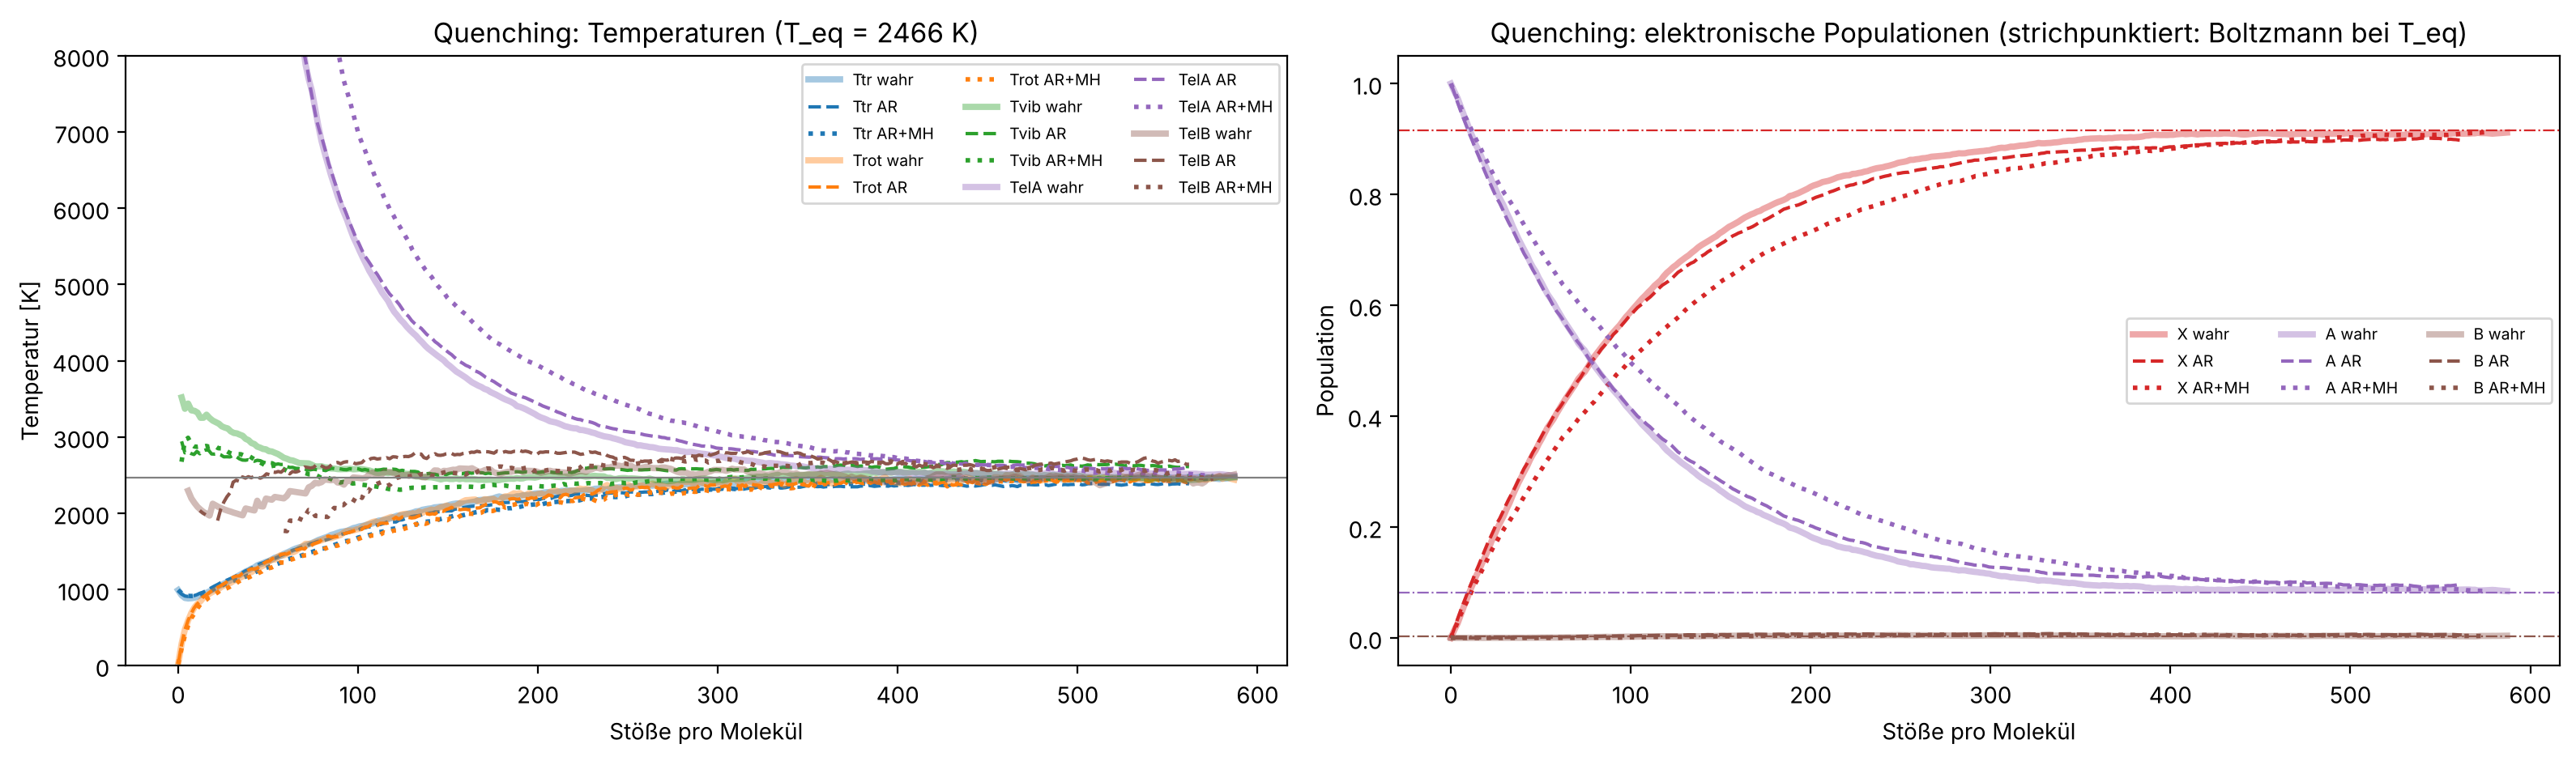

T_eq = 2466 K,  Boltzmann x_el = [0.915  0.0814 0.0036]
  true  : T_tr=2455  T_rot=2457  T_vib(X)=2478  T_el(A)=2517  T_el(B)=2451  x_el=[0.9093 0.0873 0.0034]
  AR    : T_tr=2373  T_rot=2422  T_vib(X)=2642  T_el(A)=2606  T_el(B)=2648  x_el=[0.8969 0.0975 0.0056]
  AR+MH : T_tr=2449  T_rot=2437  T_vib(X)=2469  T_el(A)=2556  T_el(B)=2553  x_el=[0.9038 0.0917 0.0045]
  Energy conservation (rel. drift) AR: 2.1e-14
  Energy conservation (rel. drift) AR+MH: 2.1e-14
1/e relaxation times (energy) in collisions per molecule, Quenching:
  Rotation      true =   68.1   AR =   67.5   AR+MH =   82.0
  Vibration     true =   69.2   AR =   79.0   AR+MH =  108.7
  electronic    true =   96.3   AR =   95.8   AR+MH =  123.6


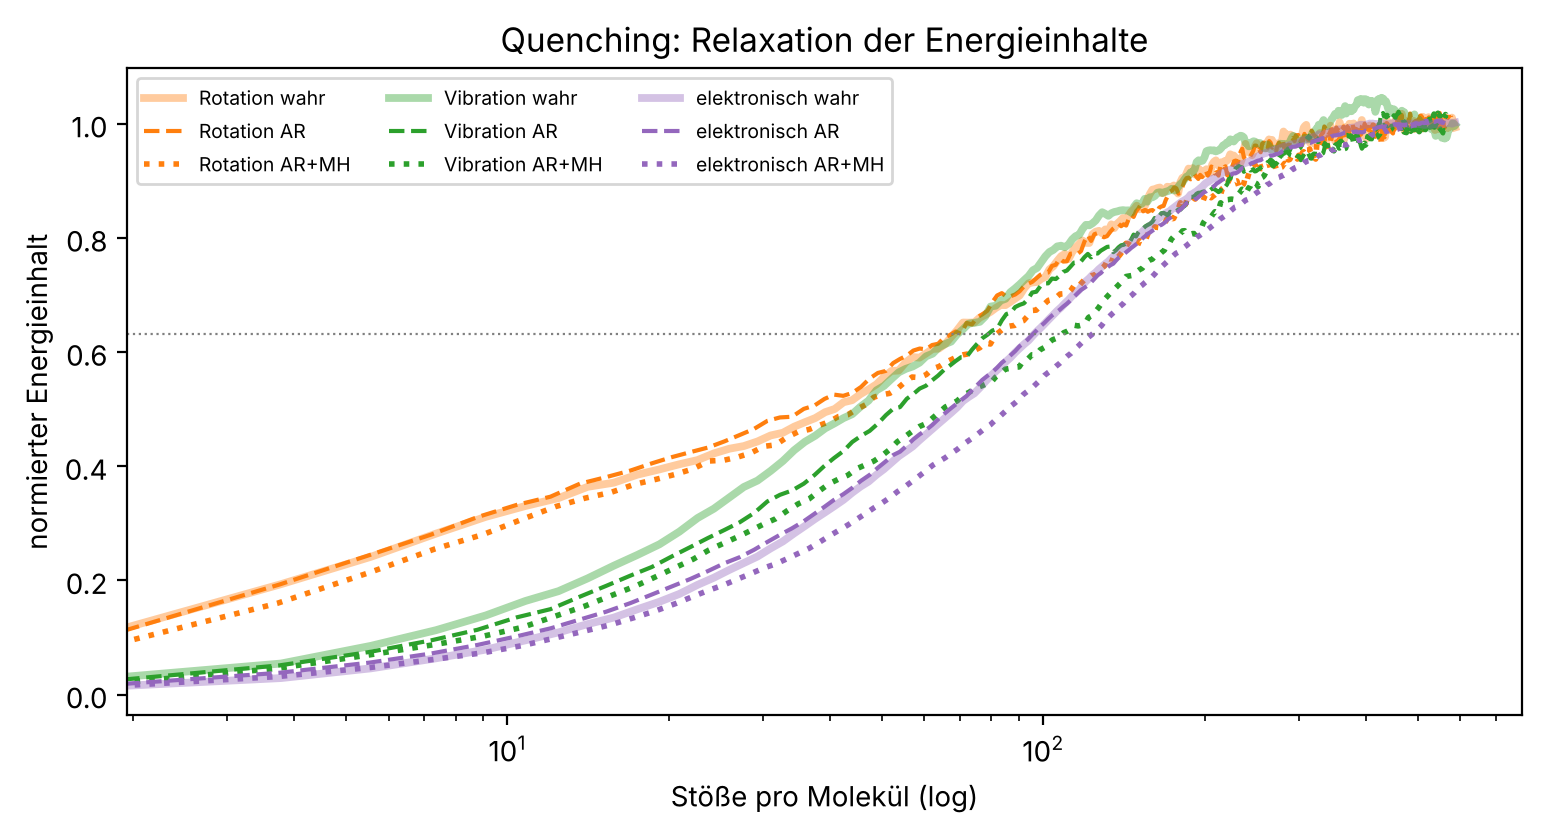

true  : T_el(A) defined from ~39.2 collisions per molecule, there T_el(A) = 32595 K
AR    : T_el(A) defined from ~37.4 collisions per molecule, there T_el(A) = 37764 K
AR+MH : T_el(A) defined from ~46.6 collisions per molecule, there T_el(A) = 36409 K


In [ ]:
snaps2 = (5, 25, 80)
runs2, final2 = {}, {}
for name, sampler in [("true", lambda i, e: true_sampler(i, e, rng_true)),
                      ("AR", model_sampler),
                      ("AR+MH", (mh2 := MHSampler()))]:
    t0 = time.time()
    runs2[name], final2[name] = run_heatbath(sampler, 1000.0, idx(1, 0, 0), n_steps=7000, snap_at=snaps2)
    print(f"{name}: {time.time()-t0:.0f}s")
print(mh2.report())
T_eq2 = plot_run(runs2, "Quenching", T_ylim=(0, 8000))
plot_energy_relaxation(runs2, "Quenching")

# When does the population inversion end (x_A/x_X < g_A/g_X), and how hot is T_el(A) then?
for name, r in runs2.items():
    k = np.argmax(np.isfinite(r["TelA"]))
    print(f"{name:6s}: T_el(A) defined from ~{r['t'][k]:.1f} collisions per molecule, there T_el(A) = {r['TelA'][k]:.0f} K")

### Vibrational distribution in the ground state X during quenching

For comparison, the Boltzmann distribution at the *instantaneous* translational temperature is shown. A deviation indicates that vibration is not in equilibrium with translation.

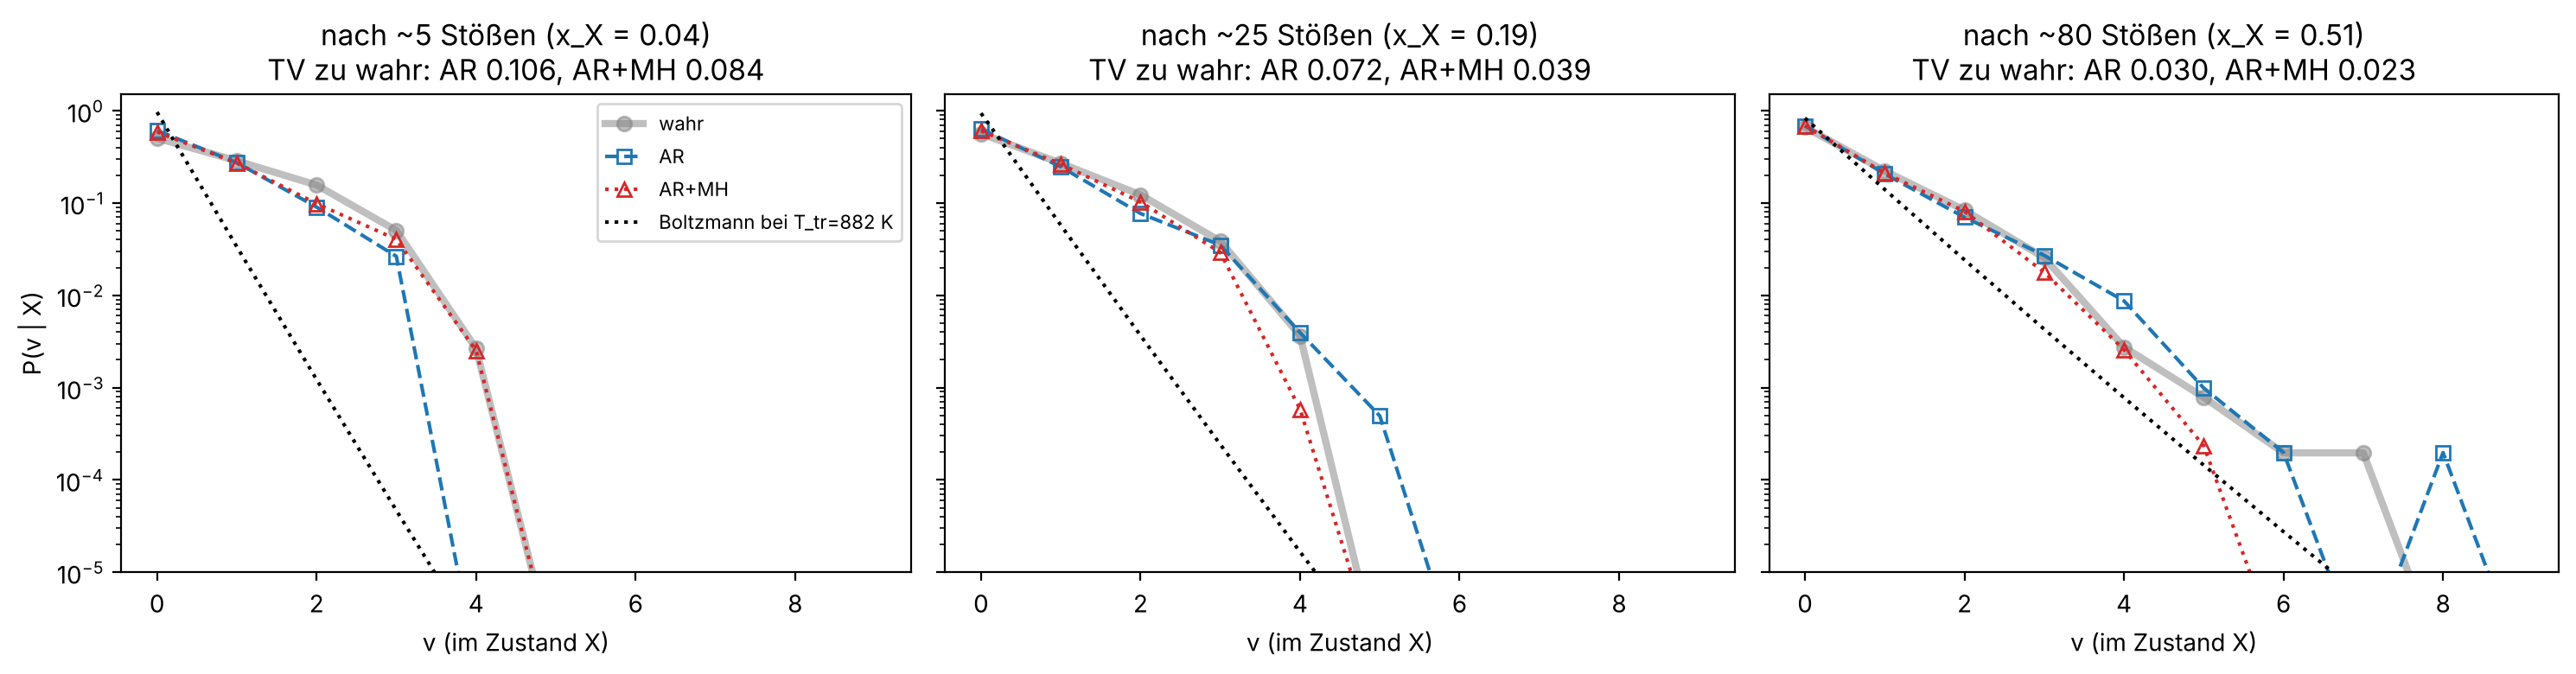

Quench time (1/e) in collisions per molecule:  true = 97.2,  AR = 98.4,  AR+MH = 126.3


In [ ]:
fig, ax = plt.subplots(1, len(snaps2), figsize=(5 * len(snaps2), 4), sharey=True)
tv = lambda p, q: 0.5 * np.abs(p - q).sum()
SNAPSTY = {"true": dict(marker="o", color="gray", lw=3, alpha=0.5), "AR": dict(marker="s", color="C0", ls="--", mfc="none"),
           "AR+MH": dict(marker="^", color="C3", ls=":", mfc="none")}
for c, s in enumerate(snaps2):
    k = np.argmin(np.abs(runs2["true"]["t"] - s))
    T_now = runs2["true"]["Ttr"][k]
    p_ref = np.exp(-eps_vib[0] / T_now); p_ref /= p_ref.sum()
    pops = {}
    for name, r in runs2.items():
        st = r["snaps"][s]; stX = st[e_of[st] == 0]
        pops[name] = np.bincount(v_of[stX], minlength=NV) / max(len(stX), 1)
        ax[c].semilogy(v_idx, np.clip(pops[name], 1e-6, None), label=name, **SNAPSTY[name])
    ax[c].semilogy(v_idx, p_ref, "k:", label=f"Boltzmann at T_tr={T_now:.0f} K")
    x_X = np.mean(e_of[runs2["true"]["snaps"][s]] == 0)
    ax[c].set_title(f"after ~{s} collisions (x_X = {x_X:.2f})\nTV to true: AR {tv(pops['AR'], pops['true']):.3f}, "
                    f"AR+MH {tv(pops['AR+MH'], pops['true']):.3f}")
    ax[c].set_xlabel("v (in state X)"); ax[c].set_ylim(1e-5, 1.5)
ax[0].set_ylabel("P(v | X)"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Quench time: when has x_A dropped to 1/e of its excess over equilibrium?
def quench_time(r, xA_eq):
    y = (r["xel"][:, 1] - xA_eq) / (r["xel"][0, 1] - xA_eq)
    k = np.argmax(y < np.exp(-1))
    return np.interp(np.exp(-1), [y[k], y[k-1]], [r["t"][k], r["t"][k-1]])
xA_eq = boltzmann_pops(T_eq2)[0][1]
print("Quench time (1/e) in collisions per molecule:  " +
      ",  ".join(f"{n} = {quench_time(r, xA_eq):.1f}" for n, r in runs2.items()))

**Interpretation**

- **Quench rate:** Whether the AR model gets the time scale right depends on the rare electronic transitions. An error of a few percent in $p_\theta(e' \mid \cdot)$ carries over directly to the quench time. Deviations of a few percent are typical here (see output above).
- **Order of the modes (energy plots):** During heating, rotation relaxes in ~5 collisions, vibration and electronic excitation only after ~70–75. Rotation **overshoots** (normalized energy content up to 1.2): it is initially in equilibrium with the still-hot translation and then cools down together with it, while vibration and electronic modes slowly take up energy. In quenching it is the other way round: translation and rotation are heated only by quenching and therefore follow it on a similar time scale.
- **Metropolis-Hastings (AR+MH):** The **equilibrium** becomes clearly better. During heating, all temperatures and populations match the truth within noise, and the systematic shift of the plain AR model (e.g. $T_\text{vib}(X)$ by +6 %) disappears. The price is the **dynamics**: ~20–25 % of electronic proposals are rejected, and these collisions become elastic. Vibration, electronic excitation and quenching thus become 20–30 % slower (quench time ~126 instead of ~97 collisions). This is the typical trade-off: MH guarantees the thermodynamics exactly but distorts the kinetics, and the more so the worse the network satisfies detailed balance on its own. The remedy is a better $q_\theta$: more data for the rare channels, a penalty term for detailed balance, or training through the MH step (idea 2). Then the acceptance rate approaches 1 and both are correct.
- **E-V transfer:** At the start, the X vibration is clearly **hotter than translation**, because freshly quenched molecules preferentially land in $v = 1\dots3$. This is pure state-to-state information. A model that puts electronic energy wholesale into translation or distributes it thermally cannot capture this.
- **Equilibrium:** The residual population in A ($\sim g_A e^{-T_A/T}$) is sensitive to violations of detailed balance in the $\Delta e \neq 0$ transitions (cf. 6b).

## 9. Ideas for further exploration

1. **Radiative decay:** Add A → X via spontaneous emission, with a probability $1 - e^{-A_{21}\Delta t}$ per time step, independent of collisions. The energy leaves the system (optically thin), and there is *no* detailed balance for this channel. It therefore does not belong in the AR collision model but in DSMC as a separate step. Compare collisional quenching and radiation (Stern-Volmer behavior).
2. **Train through the MH step:** Fit not $q_\theta$ but the effective transition probability $q_\theta \cdot A$ (plus the elastic remainder) to the data. Then both equilibrium **and** dynamics are correct. With 1500 states, the sum over all final states is still feasible.
3. **Weighting rare channels:** Oversample $\Delta e \neq 0$ trajectories in training (corrected via sample weights in `model.fit`) and check whether the quench time becomes more accurate.
4. **Train without uniformly distributed initial states** (`frac_uniform=0`): How well does the network extrapolate in the quenching scenario?
5. **Spin selection rules:** Make X ↔ B "forbidden" ($K_{XB} = 0$). Then B has to relax via A, producing a cascade.
6. **Electron collisions:** Add a second collision partner (electrons) with its own AR model. This is the typical situation in plasmas and during reentry.